# Soybean Maturity Prediction from UAV Time-Series Imagery — Pretrained CNN Inference

**Paper:** *High-Throughput Phenotyping of Soybean Maturity Using Time Series UAV Imagery and Convolutional Neural Networks*, **Remote Sensing** 12(21):3617 (2020), doi:[10.3390/rs12213617](https://doi.org/10.3390/rs12213617)

**Author code:** [RodrigoAgronomia/SoybeanMaturityModel](https://github.com/RodrigoAgronomia/SoybeanMaturityModel) pinned at commit `84e0e83aa14592c89d757332ea6936c695f2b1f6` (verified 2026-11-03).

## Purpose and exact scope

Run the authors' **pretrained two-stage CNN** (`MaturityPrediction` in `python/model.py`, weights `data/model_2018.pth`) on **one example trial folder** `examples/2019_F05A` (100 plots × 6 UAV dates: DOY 253–273) and export the per-plot maturity predictions, following the authors' own inference notebook `python/Predict_Maturiy.ipynb`.

**This is a partial demonstration only:** pretrained inference on one field. The example folder contains **no ground-truth labels**, so the paper's dataset-level validation (RMSE < 2 days in 4/5 trials) is **not** reproduced here.

**AI-assisted adaptation notice:** This Colab notebook is an adaptation of the authors' `Predict_Maturiy.ipynb` (commit `84e0e83aa14592c89d757332ea6936c695f2b1f6`); the authors did not provide this exact notebook. The author model/dataset code is used verbatim from the pinned commit. The executed example and listed checks were validated, but untested behavior is not guaranteed.
**（日本語）本ノートブックは著者の `Predict_Maturiy.ipynb`（コミット `84e0e83aa14592c89d757332ea6936c695f2b1f6`）を Colab 用に脚色したものであり、著者自身が提供したものではありません。モデル・データセットコードは pinned コミットからそのまま使用しています。検証済みの実行例以外の動作は保証されません。**

## Runtime selection — CPU (no GPU needed)

The model is a very small CNN (27 KB of weights, ≤ 32 channels) and the authors' inference code contains no CUDA path, so a **standard CPU runtime is faithful and sufficient**. Select **Runtime → Change runtime type → CPU** (the default) and then **Runtime → Run all**.

**（日本語）モデルは小型 CNN（重み 27 KB）で GPU 不要です。標準の CPU ランタイムで「ランタイム → すべてのセルを実行」してください。** Expected: ~5 minutes end-to-end, ~6.4 MB of downloads (one example field + weights).

### Cell: environment report

Prints the Python, PyTorch and OpenCV versions of the current runtime, so the executed output records the actual environment. **（日本語）実行環境（Python / PyTorch / OpenCV のバージョン）を確認します。**

In [ ]:
import sys, importlib.util
print("Python:", sys.version)
for pkg in ["torch", "cv2", "numpy", "pandas", "matplotlib"]:
    spec = importlib.util.find_spec(pkg)
    if spec is None:
        print(f"{pkg}: NOT INSTALLED")
    else:
        m = importlib.import_module(pkg)
        print(f"{pkg}: {getattr(m, '__version__', 'unknown')}")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


torch: 2.11.0+cpu
cv2: 4.14.0
numpy: 2.4.6


pandas: 2.2.3
matplotlib: 3.10.0


### Cell: dependency guard (OpenCV)

`python/dataset.py` reads plot images with OpenCV (`cv2.imread`). Colab runtimes normally ship OpenCV preinstalled; this cell installs `opencv-python-headless` only if the import is missing. **（日本語）OpenCV が無い場合のみ `opencv-python-headless` をインストールします（通常はプリインストール済み）。**

In [ ]:
import importlib.util
if importlib.util.find_spec("cv2") is None:
    print("cv2 missing -> installing opencv-python-headless")
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless"], check=True)
else:
    print("cv2 already available")

cv2 already available


## Minimal input and weight acquisition (inside Colab, pinned commit)

All data comes from the author repository **pinned at commit `84e0e83aa14592c89d757332ea6936c695f2b1f6`** (the commit verified for this paper). Instead of the authors' shallow `master` clone, we use a **partial, blobless clone with sparse checkout** restricted to exactly what this demonstration needs:

- `python/` — author model and dataset code,
- `data/model_2018.pth` — pretrained weights (27,443 bytes),
- `examples/2019_F05A/` — one trial folder: 100 plots × 6 dates (≈ 6.3 MB).

Everything stays under `/content` on the Colab VM. **（日本語）著者リポジトリを pinned コミットに固定した部分クローン（blob 省略・スパースチェックアウト）で取得します。必要最小限の 3 項目のみで、すべて Colab VM 上の `/content` に置かれます。**

In [ ]:
%%bash
set -euo pipefail
cd /content
rm -rf SoybeanMaturityModel
git clone --quiet --filter=blob:none --no-checkout https://github.com/RodrigoAgronomia/SoybeanMaturityModel.git
cd SoybeanMaturityModel
git fetch --quiet --depth 1 origin 84e0e83aa14592c89d757332ea6936c695f2b1f6
git sparse-checkout init --cone
git sparse-checkout set python data examples/2019_F05A
git checkout --quiet --detach FETCH_HEAD
git rev-parse HEAD

84e0e83aa14592c89d757332ea6936c695f2b1f6


### Cell: pin verification

Asserts that the checked-out commit is exactly `84e0e83aa14592c89d757332ea6936c695f2b1f6`. A failed assert stops the notebook rather than silently analyzing a different revision. **（日本語）チェックアウトしたコミットが pinned コミットと一致することを検証します（一致しない場合は中断）。**

In [ ]:
import subprocess
PINNED_COMMIT = "84e0e83aa14592c89d757332ea6936c695f2b1f6"
REPO = "/content/SoybeanMaturityModel"
head = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip()
assert head == PINNED_COMMIT, f"checked-out {head} != pinned {PINNED_COMMIT}"
print("Checked out pinned commit:", head)

Checked out pinned commit: 84e0e83aa14592c89d757332ea6936c695f2b1f6


### Cell: downloaded-bytes validation

Validates the actual bytes on the Colab VM before scientific use: the weight file must be exactly 27,443 bytes (the blob size recorded from the pinned tree, not an LFS pointer), and `examples/2019_F05A` must contain exactly 600 JPEGs (100 plots × 6 dates). **（日本語）ダウンロードした実バイトを検証します：重みファイルのサイズ、JPEG 枚数（100 プロット × 6 日）、日付（DOY）の一致を確認します。**

In [ ]:
import os
WEIGHTS = os.path.join(REPO, "data", "model_2018.pth")
size = os.path.getsize(WEIGHTS)
assert size == 27443, f"unexpected weight size {size} (expected 27443; LFS pointer or wrong file?)"
with open(WEIGHTS, "rb") as f:
    assert f.read(20)[:4] != "GITL", "looks like a Git LFS pointer"
IMG_DIR = os.path.join(REPO, "examples", "2019_F05A")
names = sorted(os.listdir(IMG_DIR))
jpgs = [n for n in names if n.lower().endswith(".jpg")]
assert len(jpgs) == 600, f"expected 600 jpgs, got {len(jpgs)}"
plots = {}
for n in jpgs:
    plots.setdefault(n[:-8], set()).add(int(n[-7:-4]))
doy_sets = {frozenset(v) for v in plots.values()}
assert len(plots) == 100 and len(doy_sets) == 1, "unexpected plot/date structure"
doys = sorted(next(iter(doy_sets)))
print(f"weight OK: {size} bytes; plots: {len(plots)}; DOYs per plot: {doys}")

weight OK: 27443 bytes; plots: 100; DOYs per plot: [253, 257, 261, 266, 269, 273]


## Load the author's model and pretrained weights

The author modules (`model.py`, `dataset.py`) are imported **verbatim** from the pinned clone — no paraphrased reimplementation. The weights are loaded with `map_location='cpu'` (a small adaptation for runtime robustness; the authors' `torch.load(model_path)` is equivalent on CPU). **（日本語）著者の `model.py` / `dataset.py` を pinned クローンからそのまま import し、学習済み重み `model_2018.pth` を読み込みます。**

In [ ]:
import sys, torch
sys.path.insert(0, os.path.join(REPO, "python"))
from model import MaturityPrediction
from dataset import MyDataset

model = MaturityPrediction()
state = torch.load(WEIGHTS, map_location="cpu", weights_only=True)
model.load_state_dict(state)
model.eval()
n_params = sum(p.numel() for p in model.parameters())
print(f"Model OK — {n_params:,} parameters")

Model OK — 5,682 parameters


## Input preview — one plot's UAV time series

Preview the actual sample **before** inference: plot `F05A_0000` of trial `2019_F05A`, one image per flight date (DOY 253 → 273). `cv2` reads BGR, so channels are converted to RGB for display only — the model receives the untouched BGR arrays exactly as the author's `MyDataset` provides them. **（日本語）推論前に実際の入力を確認します：プロット `F05A_0000` の 6 日分（DOY 253–273）の UAV 画像。表示のみ RGB 変換し、モデルには著者コードどおり BGR のまま渡します。**

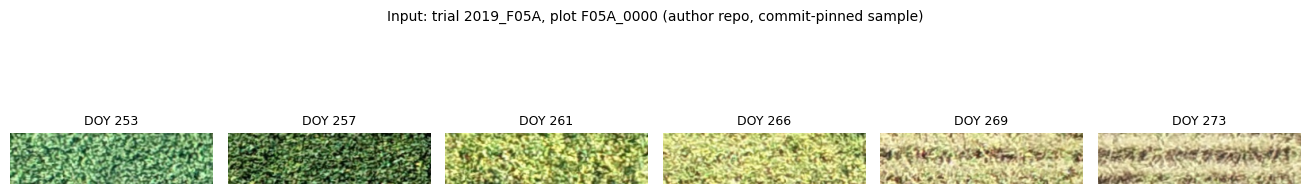

image shape (H, W, C): (64, 256, 3)


In [ ]:
import cv2
import matplotlib.pyplot as plt

SAMPLE_PLOT = "F05A_0000"
sample_files = sorted(n for n in jpgs if n.startswith(SAMPLE_PLOT + "_"))
fig, axes = plt.subplots(1, len(sample_files), figsize=(2.2 * len(sample_files), 2.8))
for ax, name in zip(axes, sample_files):
    bgr = cv2.imread(os.path.join(IMG_DIR, name))
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    ax.set_title(f"DOY {name[-7:-4]}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"Input: trial 2019_F05A, plot {SAMPLE_PLOT} (author repo, commit-pinned sample)", fontsize=10)
fig.tight_layout()
plt.show()
print("image shape (H, W, C):", bgr.shape)

## Pretrained inference on all 100 plots

Reproduces the authors' prediction loop from `Predict_Maturiy.ipynb` on this one field: `MyDataset` stacks each plot's 6 date images (normalized `(x−128)/35`, dates encoded as `0.1 × DOY`), the single-date head scores each date, the model selects its **5 best dates**, and the multi-date head predicts the maturity value `Mat` per plot. Results are exported to CSV exactly as the authors do. **（日本語）著者の推論ループをこの 1 试験区に対してそのまま実行します。各プロットの 6 日分画像からモデルが最良 5 日を選択し、成熟度 `Mat` を予測して CSV に保存します。**

In [ ]:
from tqdm.auto import tqdm
import numpy as np
import pandas as pd

img_dir = IMG_DIR  # examples/2019_F05A
test_dataset = MyDataset(img_dir)
preds_list = []
for Plot_ID, images, img_dates in tqdm(test_dataset):
    with torch.no_grad():  # inference only, no gradients
        pred = model(images[None], img_dates)
    preds_list.append({"Plot_ID": Plot_ID, "Mat": np.round(pred.data.item(), 1)})

df_pred = pd.DataFrame(preds_list)
csv_path = "/content/2019_F05A_predictions.csv"
df_pred.to_csv(csv_path, index=False)
print(f"predicted {len(df_pred)} plots -> {csv_path}")

  0%|          | 0/100 [00:00<?, ?it/s]

predicted 100 plots -> /content/2019_F05A_predictions.csv


### Cell: results table

Shows the first rows and summary statistics of the exported predictions, exactly as the authors' CSV column `Mat`. **Unit note:** the authors' code consumes dates encoded as `0.1 × DOY` internally, but the output **unit convention of `Mat` cannot be verified from the available sources** — the example folder contains no ground-truth labels and the paper full text was not readable, so no conversion to day-of-year is applied here. `Mat` is reported raw, as in the authors' pipeline. **（日本語）予測結果の表と要約統計を著者の CSV 列 `Mat` のまま表示します。出力 `Mat` の単位は利用可能な資料からは検証できないため、DOY への換算は行いません。**

In [ ]:
from IPython.display import display
display(df_pred.head(10))
display(df_pred["Mat"].describe().to_frame("Mat").T)

,Plot_ID,Mat
0,F05A_0000,49.4
1,F05A_0001,42.9
2,F05A_0002,38.0
3,F05A_0003,41.8
4,F05A_0004,44.7
5,F05A_0005,40.2
6,F05A_0006,42.8
7,F05A_0007,48.9
8,F05A_0008,47.8
9,F05A_0009,46.8


,count,mean,std,min,25%,50%,75%,max
Mat,100.0,43.121,5.201851,22.1,39.375,44.3,47.5,50.8


### Cell: prediction distribution (additional visualization)

A histogram of the 100 predicted maturity values for trial `2019_F05A`. This graph is **created for this notebook** — it is not a figure from the paper and not a reproduced published result; with one field and no ground truth it only shows the spread of predictions. **（日本語）100 プロットの予測値の分布（ヒストグラム）。本ノートブックで追加作成した可視化であり、論文の図ではありません。**

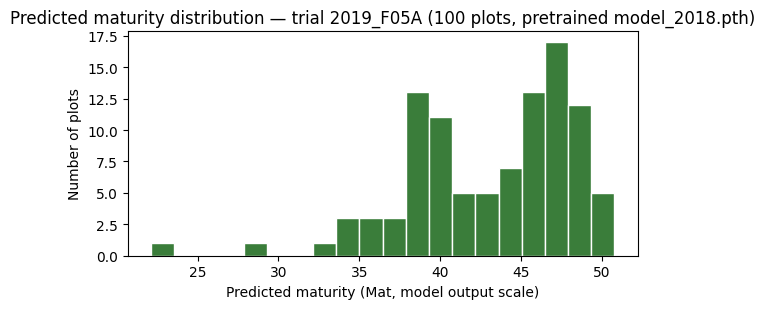

In [ ]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(df_pred["Mat"], bins=20, color="#3a7d3a", edgecolor="white")
ax.set_xlabel("Predicted maturity (Mat, model output scale)")
ax.set_ylabel("Number of plots")
ax.set_title("Predicted maturity distribution — trial 2019_F05A (100 plots, pretrained model_2018.pth)")
fig.tight_layout()
plt.show()

### Cell: input image with prediction overlay

Overlays the plot's predicted maturity on one of its real input images (DOY 273, the latest date). The image is an **original sample input**; the text box is a **model prediction produced above**, added by this notebook for readability. **（日本語）実入力画像（DOY 273）に上で得た予測値を重ねて表示します。画像は原本サンプル、注記は本ノートブックの予測結果です。**

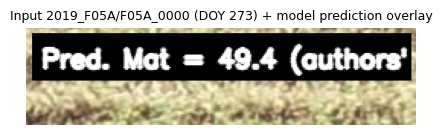

overlay text = Pred. Mat = 49.4 (authors' output scale)


In [ ]:
overlay_name = f"{SAMPLE_PLOT}_273.jpg"  # latest date of this trial
bgr = cv2.imread(os.path.join(IMG_DIR, overlay_name))
pred_row = df_pred.loc[df_pred["Plot_ID"] == SAMPLE_PLOT].iloc[0]
text = f"Pred. Mat = {pred_row['Mat']:.1f} (authors' output scale)"
h, w = bgr.shape[:2]
cv2.rectangle(bgr, (4, 4), (w - 4, 34), (0, 0, 0), -1)
cv2.putText(bgr, text, (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2, cv2.LINE_AA)
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
ax.set_title(f"Input 2019_F05A/{SAMPLE_PLOT} (DOY 273) + model prediction overlay", fontsize=9)
ax.axis("off")
fig.tight_layout()
plt.show()
print("overlay text =", text)

## Interpretation, differences from the paper, validation record

**What was executed.** The authors' pretrained model (`data/model_2018.pth`) ran end-to-end on the pinned sample `examples/2019_F05A` (100 plots × 6 dates) on a Colab CPU runtime, and the per-plot `Mat` predictions were exported to `/content/2019_F05A_predictions.csv`.

**Differences from the paper / authors' notebook (all documented adaptations):**
1. One trial folder instead of the authors' eight example fields (minimal-example rule); the per-plot loop is unchanged.
2. The repository is pinned to commit `84e0e83` with a sparse partial clone, instead of `--depth 1` of `master`.
3. `torch.load(..., map_location='cpu', weights_only=True)` for runtime robustness.
4. The preview, distribution graph, and overlay are notebook additions (clearly labeled); the paper's figures are not reproduced.

**Not reproduced / unverified:** dataset-level accuracy (RMSE < 2 days in 4/5 trials), the two countries/three seasons validation, the uncertainty-method comparison, and the ground-truth rating protocol — the examples carry no labels and the full text was not needed for this inference-only demonstration. The **unit/scale of the `Mat` output is unverified** (no labels in the examples; full text unavailable), so `Mat` is reported exactly as the authors' pipeline emits it. The repository has **no license file** and is labeled "Temporary Repository"; reuse terms are the authors'. Attribution of the repository to the DOI rests on the investigation record plus content match (model/weights/examples structure), because the MDPI full text was not machine-readable during investigation.

**（日本語）本ノートブックは学習済みモデルを 1 试験区（100 プロット）で実行した部分再現です。論文のデータセット全体の精度検証・不確実性手法の比較は対象外です。例に正解ラベルはなく、出力 `Mat` の単位も未検証のため、著者のパイプラインの出力値をそのまま報告します。リポジトリにライセンスファイルはありません。**

**References**

- Paper: doi:[10.3390/rs12213617](https://doi.org/10.3390/rs12213617) — Remote Sensing 12(21):3617.
- Code/weights/sample: https://github.com/RodrigoAgronomia/SoybeanMaturityModel , commit `84e0e83aa14592c89d757332ea6936c695f2b1f6` (`python/model.py`, `python/dataset.py`, `python/Predict_Maturiy.ipynb`, `data/model_2018.pth`, `examples/2019_F05A/`).
- PhenoPaper investigation `p-a3eca218d6b1924e7979bac50450edd3-20260930T034538Z-3226775` was used as prior research guidance, not as primary proof.